In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("penguins")


In [3]:
print(df.shape)
print(df.dtypes)
print(df.head(3))

(344, 7)
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
dtype: object
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  


In [5]:
print(df.isna().sum())
print((df.isna().mean()) * 100)

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
species              0.000000
island               0.000000
bill_length_mm       0.581395
bill_depth_mm        0.581395
flipper_length_mm    0.581395
body_mass_g          0.581395
sex                  3.197674
dtype: float64


In [6]:
print(df[df.isna().any(axis=1)])

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
8    Adelie  Torgersen            34.1           18.1              193.0   
9    Adelie  Torgersen            42.0           20.2              190.0   
10   Adelie  Torgersen            37.8           17.1              186.0   
11   Adelie  Torgersen            37.8           17.3              180.0   
47   Adelie      Dream            37.5           18.9              179.0   
246  Gentoo     Biscoe            44.5           14.3              216.0   
286  Gentoo     Biscoe            46.2           14.4              214.0   
324  Gentoo     Biscoe            47.3           13.8              216.0   
336  Gentoo     Biscoe            44.5           15.7              217.0   
339  Gentoo     Biscoe             NaN            NaN                NaN   

     body_mass_g  sex  
3            NaN  NaN  
8         3475.0  NaN  
9         4250.

In [9]:
print(df.duplicated().sum())
print(df.describe())

0
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count      342.000000     342.000000         342.000000   342.000000
mean        43.921930      17.151170         200.915205  4201.754386
std          5.459584       1.974793          14.061714   801.954536
min         32.100000      13.100000         172.000000  2700.000000
25%         39.225000      15.600000         190.000000  3550.000000
50%         44.450000      17.300000         197.000000  4050.000000
75%         48.500000      18.700000         213.000000  4750.000000
max         59.600000      21.500000         231.000000  6300.000000


In [ ]:
print(df["species"].value_counts())
print(df["island"].value_counts())
print(df["sex"].value_counts(dropna=False))

#No spelling or space problems here (only the spelling of all text column's first letter capitalized)

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
sex
Male      168
Female    165
NaN        11
Name: count, dtype: int64


In [ ]:
clean = df.copy()

clean = clean.dropna(subset=["bill_length_mm" , "bill_depth_mm", "flipper_length_mm", "body_mass_g"])
print(clean.shape)  

#These 2 rows have no bill, flipper or body-mass measurements, so they carry nothing for the analysis.

(342, 7)


In [27]:
print(clean["sex"].isna().sum())

9


In [30]:
print(clean["body_mass_g"].mean())
print(clean["body_mass_g"].median())

4201.754385964912
4050.0


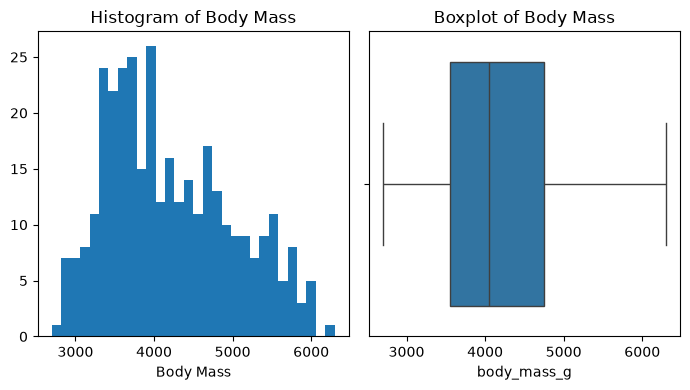

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(7, 4))
axes[0].hist(clean["body_mass_g"], bins=30)
axes[0].set_title("Histogram of Body Mass")
axes[0].set_xlabel("Body Mass")

sns.boxplot(x=clean["body_mass_g"], ax=axes[1])
axes[1].set_title("Boxplot of Body Mass")

plt.tight_layout()
plt.show()

In [31]:
def count_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outside = (series < low) | (series > high)
    return int(outside.sum())

In [35]:
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

for cols in num_cols:
    print(cols, count_outliers(clean[cols]))

bill_length_mm 0
bill_depth_mm 0
flipper_length_mm 0
body_mass_g 0


In [38]:
print(clean.groupby("species")[num_cols].mean().round(1))

           bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
species                                                                 
Adelie               38.8           18.3              190.0       3700.7
Chinstrap            48.8           18.4              195.8       3733.1
Gentoo               47.5           15.0              217.2       5076.0


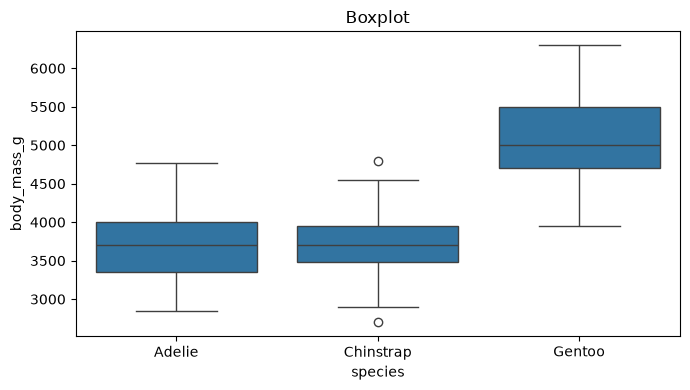

1375.4


In [67]:
fig, axes = plt.subplots(figsize=(7, 4))
sns.boxplot(data=clean, x="species", y="body_mass_g")
plt.title("Boxplot")
plt.tight_layout()
plt.show()

#Species Gentoo is the heaviest and it is differ by 1375.3g 
gentoo_mass = clean[clean["species"] == "Gentoo"]["body_mass_g"].mean()
adelie_mass = clean[clean["species"] == "Adelie"]["body_mass_g"].mean()
print(round(gentoo_mass - adelie_mass, 1))


In [58]:
live = pd.crosstab(clean["species"], clean["island"])
print(live)

island     Biscoe  Dream  Torgersen
species                            
Adelie         44     56         51
Chinstrap       0     68          0
Gentoo        123      0          0


In [ ]:
print(clean.groupby("sex")["body_mass_g"].mean())
#Male weighs more than female and this answer excluded 9 null values

sex
Female    3862.272727
Male      4545.684524
Name: body_mass_g, dtype: float64


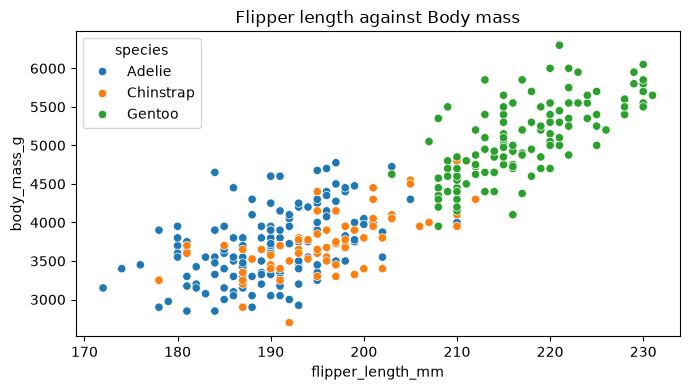

In [ ]:
fig, axes = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=clean, x="flipper_length_mm", y="body_mass_g", hue="species")
plt.title("Flipper length against Body mass")
plt.tight_layout()
plt.show()

#Almost every Gentoo species flipper length's are 200 and above. 
#This tells that the more the weight the more the length of flipper.


In [63]:
corr = clean[num_cols].corr()
print(corr.round(2))

                   bill_length_mm  bill_depth_mm  flipper_length_mm  \
bill_length_mm               1.00          -0.24               0.66   
bill_depth_mm               -0.24           1.00              -0.58   
flipper_length_mm            0.66          -0.58               1.00   
body_mass_g                  0.60          -0.47               0.87   

                   body_mass_g  
bill_length_mm            0.60  
bill_depth_mm            -0.47  
flipper_length_mm         0.87  
body_mass_g               1.00  


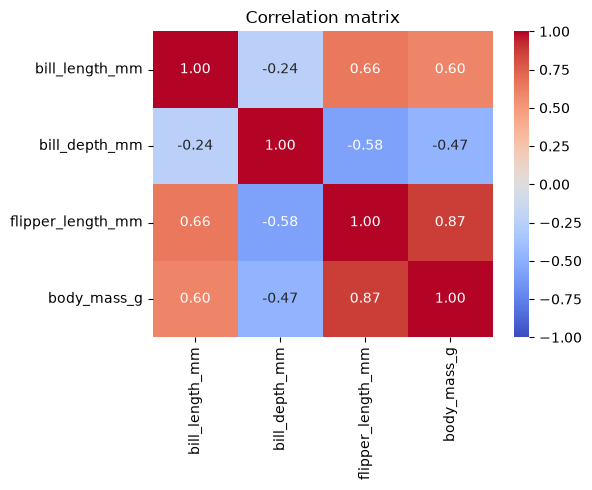

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

#Flipper length and body mass is the strongest pair with 0.87 the numbers are 
#highly positive which means the more the weight, the more the length of flipper.

## Findings

1. Gentoo penguins are the heaviest: 5076 g on average, about 1375 g
   more than Adelie (3701 g). Chinstrap (3733 g) weigh almost the same
   as Adelie.
2. Flipper length and body mass have the strongest link of the four
   measurements (correlation 0.87). Gentoo flippers average 217.2 mm,
   against 190.0 mm for Adelie.
3. Males are heavier than females: 4546 g vs 3862 g, a difference of
   about 683 g (among the 333 penguins with known sex).
4. The island identifies two of the three species: all 123 Gentoo are
   on Biscoe and all 68 Chinstrap on Dream, while Adelie live on all
   three islands (44, 56 and 51).
5. The measurements are clean: 0 duplicates and 0 IQR outliers in all
   four numeric columns. Only 2 of 344 rows (0.6%) had no
   measurements, and they were dropped.

Caveats
- Sex is unknown for 9 penguins, so the male vs female comparison
  covers 333 of the 342 penguins. Also, correlations such as 0.87 show
  that two things move together, not that one causes the other.
- The groups are different sizes (Adelie 151, Gentoo 123, Chinstrap 68),
  so the Chinstrap averages are based on fewer penguins.

Open question
- Is the weight gap between males and females about the same inside
  each species? (Mixing the species can hide or exaggerate it, as the
  bill length and depth example shows.)
